# Post-processing

In this tutorial we demonstrate the functionality and posterior operations supported by the [PostProcessing](postprocessing.rst) module by operating with the example posterior samples found in ``examples/examples_fast/Outputs``.

In [1]:
# Importing relevant modules

%matplotlib inline

from __future__ import division

from collections import OrderedDict
from scipy.stats import binom
import sys
import os
import matplotlib.pyplot as plt
import math
import numpy as np

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import xpsi
from xpsi import PostProcessing

# choose a seed for the notebook if you want caching to be useful
# and the notebook exactly reproducible
PostProcessing.set_random_seed(42)

from xpsi.global_imports import gravradius, _2pi
from xpsi.utilities.ProjectionTool import plot_projection_general
from xpsi.utilities.BackgroundTools import readSummary, plotBackgroundSpectrum
from xpsi.utilities.ConvergenceTool import plotConvergence

/=============================================\
| X-PSI: X-ray Pulse Simulation and Inference |
|---------------------------------------------|
|                Version: 3.3.0               |
|---------------------------------------------|
|      https://xpsi-group.github.io/xpsi      |
\=============================================/

Imported emcee version: 3.1.6
Imported PyMultiNest.
Imported UltraNest.
Imported GetDist version: 1.5.3
Imported nestcheck version: 0.2.1


The model can be imported with the model loader:

In [2]:
from xpsi.utilities.ModelLoader import load_model
path="../../examples/examples_fast/Modules/" 
ST = load_model( model_path=os.path.join( path ,"main.py") , execution_path=path )

Setting channels for event data...
Channels set.
Setting channels for loaded instrument response (sub)matrix...
Channels set.
An empty subspace was created. This is normal behavior - no parameters were supplied.
Creating parameter:
    > Named "phase_shift" with fixed value 0.000e+00.
    > The phase shift for the signal, a periodic parameter [cycles].
Creating parameter:
    > Named "frequency" with fixed value 3.140e+02.
    > Spin frequency [Hz].
Creating parameter:
    > Named "mass" with bounds [1.000e+00, 1.600e+00].
    > Gravitational mass [solar masses].
Creating parameter:
    > Named "radius" with bounds [1.000e+01, 1.300e+01].
    > Coordinate equatorial radius [km].
Creating parameter:
    > Named "distance" with bounds [5.000e-01, 2.000e+00].
    > Earth distance [kpc].
Creating parameter:
    > Named "cos_inclination" with bounds [0.000e+00, 1.000e+00].
    > Cosine of Earth inclination to rotation axis.
Creating parameter:
    > Named "super_colatitude" with bounds [1.0

In this case, the model_loader is equivalent to the following commands:

`sys.path.append( path )`\
`import main as ST`

However, this model loader is especially useful for loading models that use configuration file as input (see Module_generator tutorial). It is also useful to avoid cache issues when different imports share the same name, which happens when loading different models generated with the module generator. These multiple imports can be done like this for example: 

`model_names = ['ST','PDT']`\
`models = {}`\
`model_path_dict = {'ST':path-to-ST-main,'PDT':path-to-PDT-main}`\
`config_path_dict = {'ST':path-to-ST-config,'PDT':path-to-PDT-config}`\
`execution_path_dict = {'ST':path-to-ST-execution-folder,'PDT':path-to-PDT-execution-folder}`\
`for m in model_names:`\
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;`models[m] = load_model( model_path=model_path_dict[m], config_path=config_path_dict[m], execution_path=execution_path_dict[m] )`

The `execution_path` parameter allows to choose the execution folder of the import, so the relative path used by the imported module can be resolved when it is needed.

Now, let's see the free parameters for the our model.

In [3]:
ST.likelihood

Free parameters
---------------
mass: Gravitational mass [solar masses].
radius: Coordinate equatorial radius [km].
distance: Earth distance [kpc].
cos_inclination: Cosine of Earth inclination to rotation axis.
p__phase_shift: The phase of the hot region, a periodic parameter [cycles].
p__super_colatitude: The colatitude of the centre of the superseding region [radians].
p__super_radius: The angular radius of the (circular) superseding region [radians].
p__super_temperature: log10(superseding region effective temperature [K]).

Now let's set the names, the bounds and the labels of the free parameters for later use

In [4]:
# Settings names, bounds and labels
ST.names=['mass','radius','distance','cos_inclination','p__phase_shift',
          'p__super_colatitude','p__super_radius','p__super_temperature']

# We need to use the same bounds used during sampling
# They can be changed in the posterior using the param_plot_lims parameter, for example it can be set to {'radius': (9.0,12.0)} to restrict the plotting of the radius.
ST.bounds = {'mass':(1.0,1.6),
             'radius':(10,13),
             'distance':(0.5,2.0),
             'cos_inclination':(0,1),
             'p__phase_shift':(-0.25, 0.75),
             'p__super_colatitude':(0.001, math.pi/2 - 0.001),
             'p__super_radius':(0.001, math.pi/2.0 - 0.001),
             'p__super_temperature':(6., 7.)}

# Now the labels
ST.labels = {'mass': r"M\;\mathrm{[M}_{\odot}\mathrm{]}",
              'radius': r"R_{\mathrm{eq}}\;\mathrm{[km]}",
              'distance': r"D \;\mathrm{[kpc]}",
              'cos_inclination': r"\cos(i)",
              'p__phase_shift': r"\phi_{p}\;\mathrm{[cycles]}",
              'p__super_colatitude': r"\Theta_{\mathrm{spot}}\;\mathrm{[rad]}",
              'p__super_radius': r"\zeta_{\mathrm{spot}}\;\mathrm{[rad]}",
              'p__super_temperature': r"\mathrm{log10}(T_{\mathrm{spot}}\;[\mathrm{K}])"}

Let's also add the compactness because we also added that extra parameter to be derived

In [5]:
ST.names +=['compactness']
ST.bounds['compactness']=(gravradius(1.0)/16.0, 1.0/3.0)
ST.labels['compactness']= r"M/R_{\mathrm{eq}}"

Getdist settings, usually no need to be changed

In [6]:
getdist_kde_settings = {'ignore_rows': 0,
                         'min_weight_ratio': 1.0e-10,
                         'contours': [0.683, 0.954, 0.997],
                         'credible_interval_threshold': 0.001,
                         'range_ND_contour': 0,
                         'range_confidence': 0.001,
                         'fine_bins': 1024,
                         'smooth_scale_1D': 0.4,
                         'num_bins': 100,
                         'boundary_correction_order': 1,
                         'mult_bias_correction_order': 1,
                         'smooth_scale_2D': 0.4,
                         'max_corr_2D': 0.99,
                         'fine_bins_2D': 512,
                         'num_bins_2D': 40}

In [7]:
ST.likelihood

Free parameters
---------------
mass: Gravitational mass [solar masses].
radius: Coordinate equatorial radius [km].
distance: Earth distance [kpc].
cos_inclination: Cosine of Earth inclination to rotation axis.
p__phase_shift: The phase of the hot region, a periodic parameter [cycles].
p__super_colatitude: The colatitude of the centre of the superseding region [radians].
p__super_radius: The angular radius of the (circular) superseding region [radians].
p__super_temperature: log10(superseding region effective temperature [K]).

## Check the convergence

Check the convergence with a plot. There should be a mountain before a sharp rise at the end which correspond to the accumulation of the evidence followed by the addition of the left over points after sampling ended.

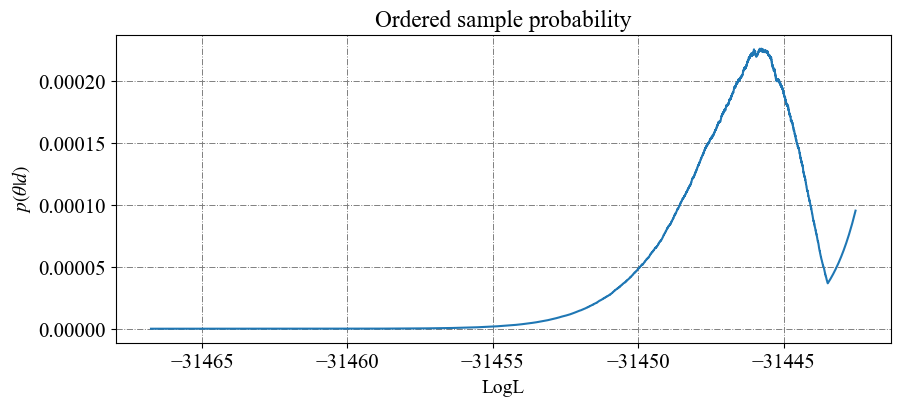

In [8]:
# Get the path and plot
samples_path = os.path.join( '../../examples/examples_fast/Outputs', 'ST_live_1000_eff_0.3_seed0' )
fig, ax = plotConvergence( samples_path=samples_path , threshold=1e-10)

## Geometry plot

Looking at the inferred best fit geometry

YOU ARE USING 1 HOT SPOT MODEL
########################
MODE:0 
Maximum Likelihood value : -80170.54704942991


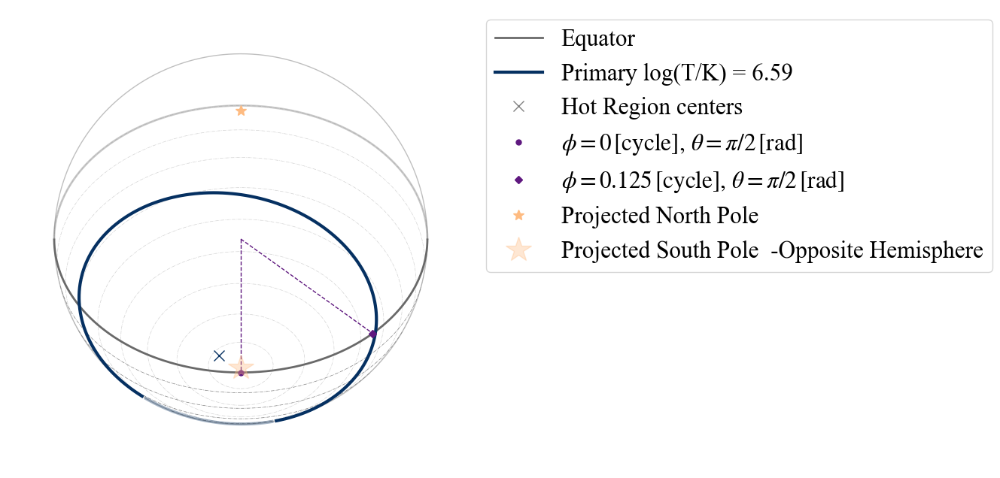

In [9]:
# Get the parameters
samples_path = os.path.join( '../../examples/examples_fast/Outputs', 'ST_live_1000_eff_0.3_seed0_v2' )
AverageP ,SigmaP, BestFitP, MAP_P = readSummary(samples_path,verbose=False)

# Do the plot
ST.likelihood(BestFitP,reinitialise=True)
ax = plot_projection_general(ST.likelihood, 'ST', "I","SP", antiphase=False, SaveFlag = False, Name = 'BestFit' )

# Do the prints
print ("########################")
print ("MODE:0 ")
print(f"Maximum Likelihood value : {ST.likelihood(BestFitP, reinitialise=True)}")

Another way to make a sky map including the deformation of the star due to its compactness is shown below. The globabal variables are specific to this ST model and need to be changed according to the model you are using.

In [10]:
class CustomPhotospherePlotter(xpsi.PhotospherePlotter):
    """ Implement method for imaging."""
    
    @property
    def global_variables(self):

        return np.array([self.photosphere['p__super_colatitude'],
                          self.photosphere['p__phase_shift'] * _2pi,
                          self.photosphere['p__super_radius'],
                          0.0, #self['p__cede_colatitude'],
                          0.0, #self['p__phase_shift'] * 2.0 * math.pi - self['p__cede_azimuth'],
                          0.0, #self['p__cede_radius'],
                          0.0, #self['s__super_colatitude'],
                          0.0, #(self['s__phase_shift'] + 0.5) * 2.0 * math.pi,
                          0.0, #self['s__super_radius'],
                          0.0, #self['s__cede_colatitude'],
                          0.0, #(self['s__phase_shift'] + 0.5) * 2.0 * math.pi - self['s__cede_azimuth'],
                          0.0, #self['s__cede_radius'],
                          self.photosphere['p__super_temperature'],
                          0.0, #self['p__cede_temperature'],
                          0.0, #self['s__super_temperature'],
                          0.0]) #self['s__cede_temperature']])

[Coordinate frequency of the mode of radiative asymmetry in the
photosphere that is assumed to generate the pulsed signal [Hz] = 3.140e+02, The phase of the hot region, a periodic parameter [cycles] = -1.880e-02, The colatitude of the centre of the superseding region [radians] = 1.451e+00, The angular radius of the (circular) superseding region [radians] = 9.311e-01, log10(superseding region effective temperature [K]) = 6.590e+00]
Imaging the star...
Commencing ray tracing and imaging...
Imaging the star and computing light-curves...
Calculating image plane boundary...
Image plane semi-major: 1.00
Image plane semi-minor: 1.00
Thread 0 is tracing annulus #0 of rays.
Thread 0 is tracing annulus #100 of rays.
Thread 0 is tracing annulus #200 of rays.
Thread 0 is tracing annulus #300 of rays.

Global ray map computed.
Coordinates transformed from Boyer-Lindquist to spherical.
Commencing imaging...Ray tracing complete.
Ray set cached.
Intensity caching complete.
Star imaged.


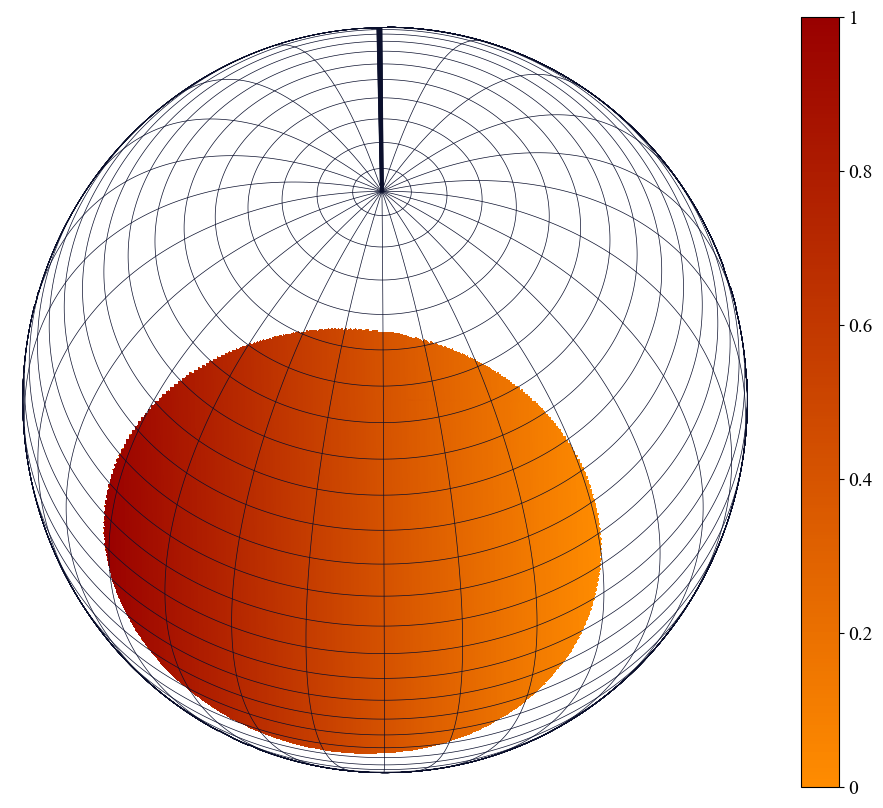

In [11]:
plotter = CustomPhotospherePlotter(ST.photosphere)
plotter.image(reimage = True,
                  cache_intensities = 1.0, # cache size limit in GBs
                  energies = np.array([0.01,0.1,0.5,1.0,2.0,5.0]),
                  phases = np.linspace(0.0, 1.0, 33),
                  sqrt_num_rays = 400,
                  threads = 4,
                  max_steps = 100000,
                  epsrel_ray = 1.0e-12)
plotter.plot_sky_map()

## Background plot

Plot the inferred background. Since the example is simple, we do not have all the samples needed in `post_equal_weight.dat` and the background distribution cannot be plotted.

Loaded the only existing signal. Please check that it is from the required instrument
Loaded the only existing signal. Please check that it is from the required instrument
Maximum counts in an energy bin : 2408.745470735736


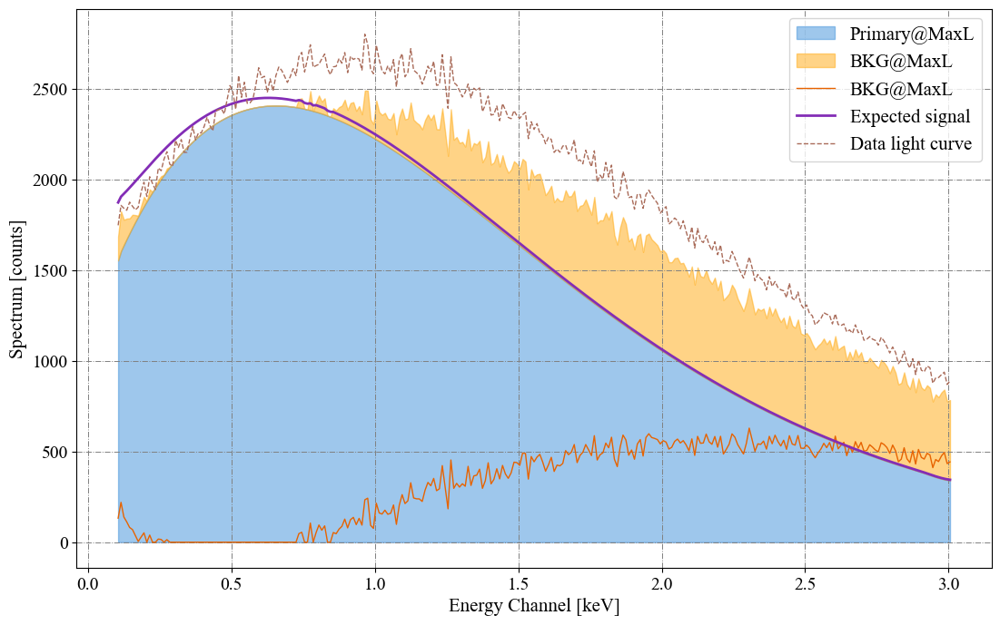

In [12]:
samples_path = os.path.join( '../../examples/examples_fast/Outputs', 'ST_live_1000_eff_0.3_seed0_v2' )
fig, ax = plotBackgroundSpectrum( XPSI_model=ST, 
                        samples_path=samples_path, 
                        InstrumentName=None,
                        plot_params=None,
                        Nsamples=200,
                        plot_range=False, 
                        yscale='linear',
                        plot_support=False)

We can choose one of the listed available colormaps for the `clrmap` parameter (`Accent`, `Dark2`, `tab10_r`, `petroff10_r` or the default colorblind friendly `petroff10`. For more information, see https://matplotlib.org/stable/users/explain/colors/colormaps.html for the three first colormaps, and https://arxiv.org/pdf/2107.02270 for the Petroff ones.), or customise the colormap with `clrmap='CustomCmap'` and defining a large list of colors for the `custcols` parameter in the `plotBackgroundSpectra` function.

## Load the run for PostProcessor

Let's now load the run

In [13]:
ST.runs = xpsi.Runs.load_runs(ID='ST',
                               run_IDs=['run'],
                               roots=['ST_live_1000_eff_0.3_seed0'],
                               base_dirs=['../../examples/examples_fast/Outputs/'],
                               use_nestcheck=[False],
                               kde_settings=getdist_kde_settings,
                               likelihood=ST.likelihood,
                               names=ST.names,
                               bounds=ST.bounds,
                               labels=ST.labels,
                               implementation='multinest',
                               overwrite_transformed=True)

Change output files to .npy to speed up post-processing


## Corner plots

Looking now at all the inferred parameters

Executing posterior density estimation...
Curating set of runs for posterior plotting...
Run set curated.
Constructing lower-triangle posterior density plot via Gaussian KDE:
plotting:  ['mass', 'radius']
plotting:  ['mass', 'distance']
plotting:  ['mass', 'cos_inclination']
plotting:  ['mass', 'p__phase_shift']
plotting:  ['mass', 'p__super_colatitude']
plotting:  ['mass', 'p__super_radius']
plotting:  ['mass', 'p__super_temperature']
plotting:  ['mass', 'compactness']
plotting:  ['radius', 'distance']
plotting:  ['radius', 'cos_inclination']
plotting:  ['radius', 'p__phase_shift']
plotting:  ['radius', 'p__super_colatitude']
plotting:  ['radius', 'p__super_radius']
plotting:  ['radius', 'p__super_temperature']
plotting:  ['radius', 'compactness']
plotting:  ['distance', 'cos_inclination']
plotting:  ['distance', 'p__phase_shift']
plotting:  ['distance', 'p__super_colatitude']
plotting:  ['distance', 'p__super_radius']
plotting:  ['distance', 'p__super_temperature']
plotting:  ['dista

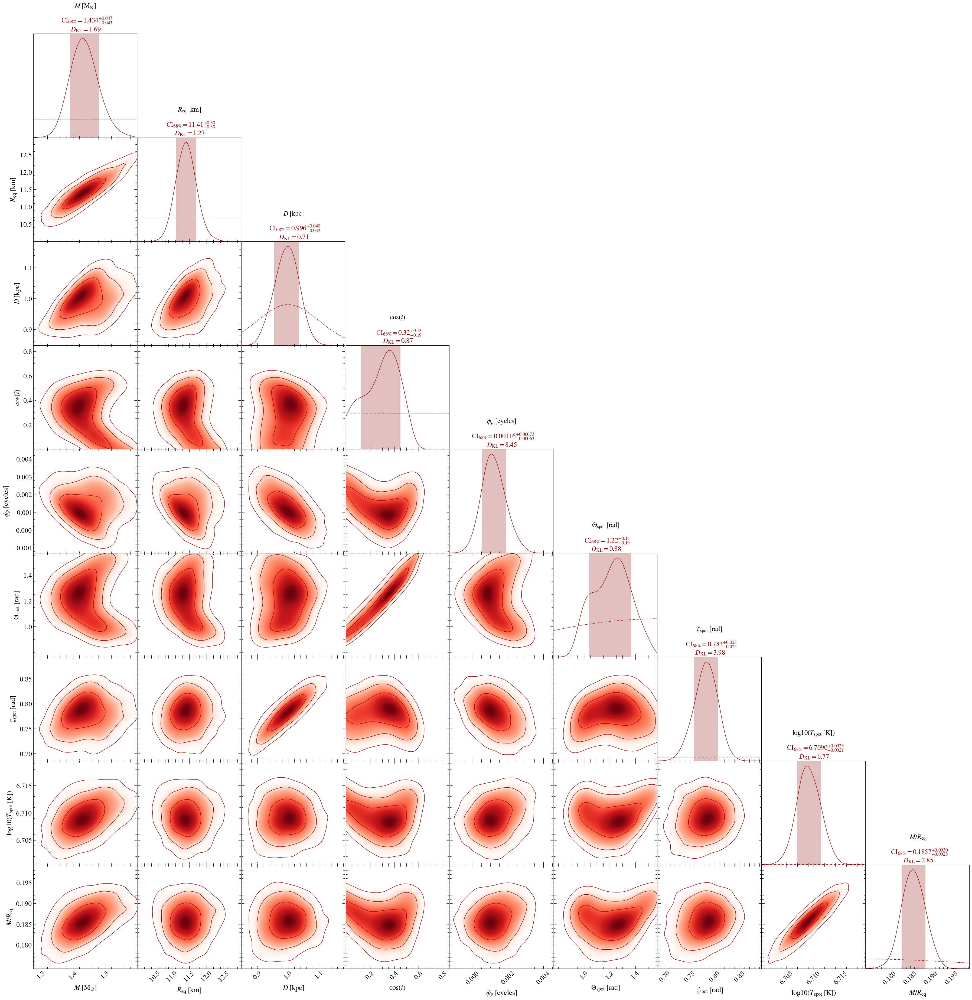

In [14]:
pp = xpsi.PostProcessing.CornerPlotter([ST.runs])
_ = pp.plot(
     params=ST.names,
    
     IDs=OrderedDict([('ST', ['run',]),]),
     prior_density=True,
     KL_divergence=True,
     ndraws=5e4,
     combine=False, combine_all=True, only_combined=False, overwrite_combined=True,
     param_plot_lims={},
     bootstrap_estimators=False,
     bootstrap_density=False,
     n_simulate=200,
     crosshairs=False,
     write=False,
     ext='.png',
     maxdots=3000,
     root_filename='run',
     credible_interval_1d=True,
     annotate_credible_interval=True,
     compute_all_intervals=False,
     sixtyeight=True,
     axis_tick_x_rotation=45.0,
     num_plot_contours=3,
     subplot_size=4.0,
     legend_corner_coords=(0.675,0.8),
     legend_frameon=False,
     scale_attrs=OrderedDict([('legend_fontsize', 2.0),
                              ('axes_labelsize', 1.35),
                              ('axes_fontsize', 'axes_labelsize'),
                             ]
                            ),
     colormap='Reds',
     shaded=-1,
     rasterized_shade=True,
     no_ylabel=True,
     no_ytick=True,
     lw=1.0,
     lw_1d=1.0,
     filled=False,
     normalize=True,
     veneer=True,
     #contour_colors=['orange'],
     tqdm_kwargs={'disable': False},
     lengthen=2.0,
     embolden=1.0,
     nx=500)


Now let's plot a subset of those parameters, say : Mass, Radius and Compactness

Executing posterior density estimation...
Curating set of runs for posterior plotting...
Run set curated.
Constructing lower-triangle posterior density plot via Gaussian KDE:
plotting:  ['mass', 'radius']
plotting:  ['mass', 'compactness']
plotting:  ['radius', 'compactness']
Adding 1D marginal prior density functions...
Plotting prior for posterior ST...
Drawing samples from the joint prior...
Samples drawn.
Estimating 1D marginal KL-divergences in bits...
mass KL-divergence = 1.6944...
radius KL-divergence = 1.2657...
compactness KL-divergence = 2.8486...
Estimated 1D marginal KL-divergences.
Added 1D marginal prior density functions.
Veneering spines and axis ticks...
Veneered.
Adding 1D marginal credible intervals...
Plotting credible regions for posterior ST...
Added 1D marginal credible intervals.
Constructed lower-triangle posterior density plot.
Posterior density estimation complete.


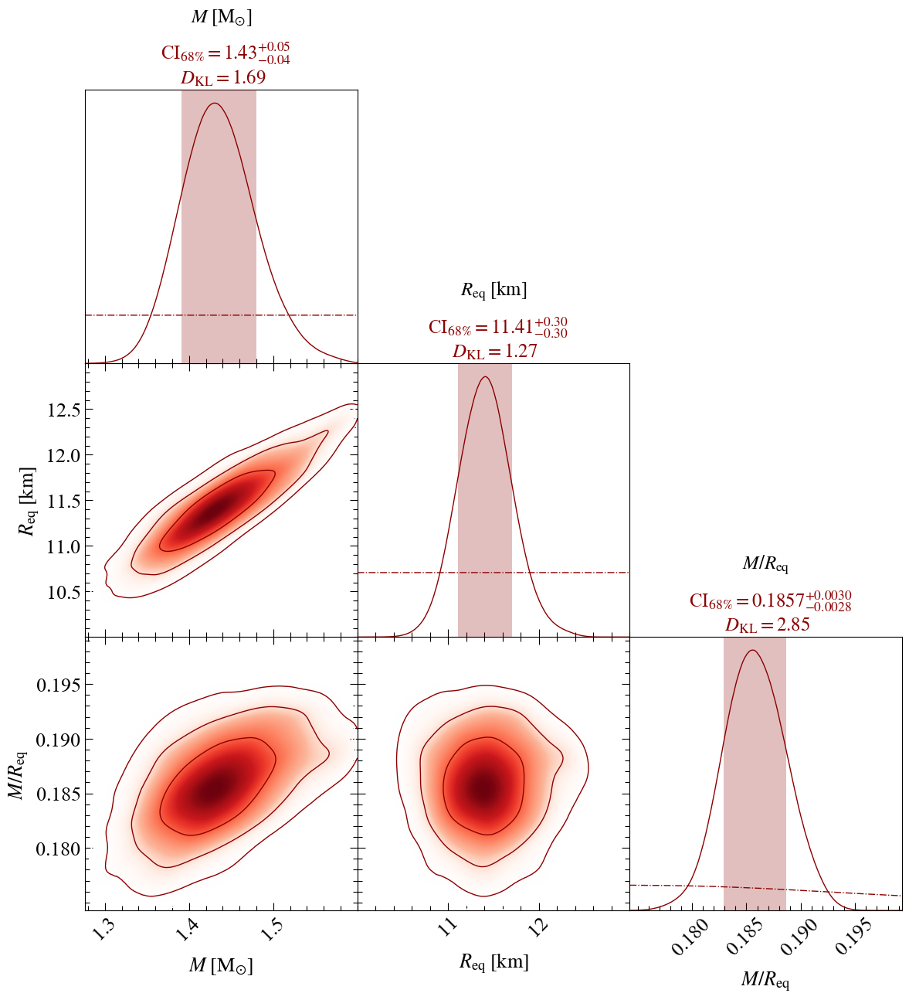

In [15]:
_ = pp.plot(
     params=["mass", "radius", "compactness"],
    
     IDs=OrderedDict([('ST', ['run',]),]),
     prior_density=True,
     KL_divergence=True,
     ndraws=5e4,
     combine=False, combine_all=True, only_combined=False, overwrite_combined=True,
     param_plot_lims={},
     bootstrap_estimators=False,
     bootstrap_density=False,
     n_simulate=200,
     crosshairs=False,
     write=False,
     ext='.png',
     maxdots=3000,
     root_filename='run',
     credible_interval_1d=True,
     annotate_credible_interval=True,
     compute_all_intervals=False,
     sixtyeight=True,
     axis_tick_x_rotation=45.0,
     num_plot_contours=3,
     subplot_size=4.0,
     legend_corner_coords=(0.675,0.8),
     legend_frameon=False,
     scale_attrs=OrderedDict([('legend_fontsize', 2.0),
                              ('axes_labelsize', 1.35),
                              ('axes_fontsize', 'axes_labelsize'),
                             ]
                            ),
      colormap='Reds',
     shaded=-1,
     rasterized_shade=True,
     no_ylabel=True,
     no_ytick=True,
     lw=1.0,
     lw_1d=1.0,
     filled=False,
     normalize=True,
     veneer=True,
     #contour_colors=['orange'],
     tqdm_kwargs={'disable': False},
     lengthen=2.0,
     embolden=1.0,
     #Adjusting the decimal precision for the reported mass interval (and automatic precision for the others):
     precisions=[2,None,None],
     nx=500)


For the sake of example, let's assume one has multiple runs for the same model and wants to plots them all on a same plot.

Here, we have two runs, one performed fixing multinest seed to 0, and the second fixing the  seed to 42.

In [16]:
# Loading the runs

ST.runs = xpsi.Runs.load_runs(ID='ST',
                               run_IDs=['run_seed0','run_seed42'],
                               roots=['ST_live_1000_eff_0.3_seed0','ST_live_1000_eff_0.3_seed42'],
                               base_dirs=['../../examples/examples_fast/Outputs/',
                                         '../../examples/examples_fast/Outputs/'],
                               use_nestcheck=[True]*2,#[True]*2,
                               kde_settings=getdist_kde_settings,
                               likelihood=ST.likelihood,
                               names=ST.names,
                               bounds=ST.bounds,
                               labels=ST.labels,
                               implementation='multinest',
                               overwrite_transformed=True)

Change output files to .npy to speed up post-processing
Change output files to .npy to speed up post-processing


Executing posterior density estimation...
Curating set of runs for posterior plotting...
Run set curated.
Constructing lower-triangle posterior density plot via Gaussian KDE:
plotting:  ['mass', 'radius']
plotting:  ['mass', 'distance']
plotting:  ['mass', 'cos_inclination']
plotting:  ['mass', 'p__phase_shift']
plotting:  ['mass', 'p__super_colatitude']
plotting:  ['mass', 'p__super_radius']
plotting:  ['mass', 'p__super_temperature']
plotting:  ['mass', 'compactness']
plotting:  ['radius', 'distance']
plotting:  ['radius', 'cos_inclination']
plotting:  ['radius', 'p__phase_shift']
plotting:  ['radius', 'p__super_colatitude']
plotting:  ['radius', 'p__super_radius']
plotting:  ['radius', 'p__super_temperature']
plotting:  ['radius', 'compactness']
plotting:  ['distance', 'cos_inclination']
plotting:  ['distance', 'p__phase_shift']
plotting:  ['distance', 'p__super_colatitude']
plotting:  ['distance', 'p__super_radius']
plotting:  ['distance', 'p__super_temperature']
plotting:  ['dista

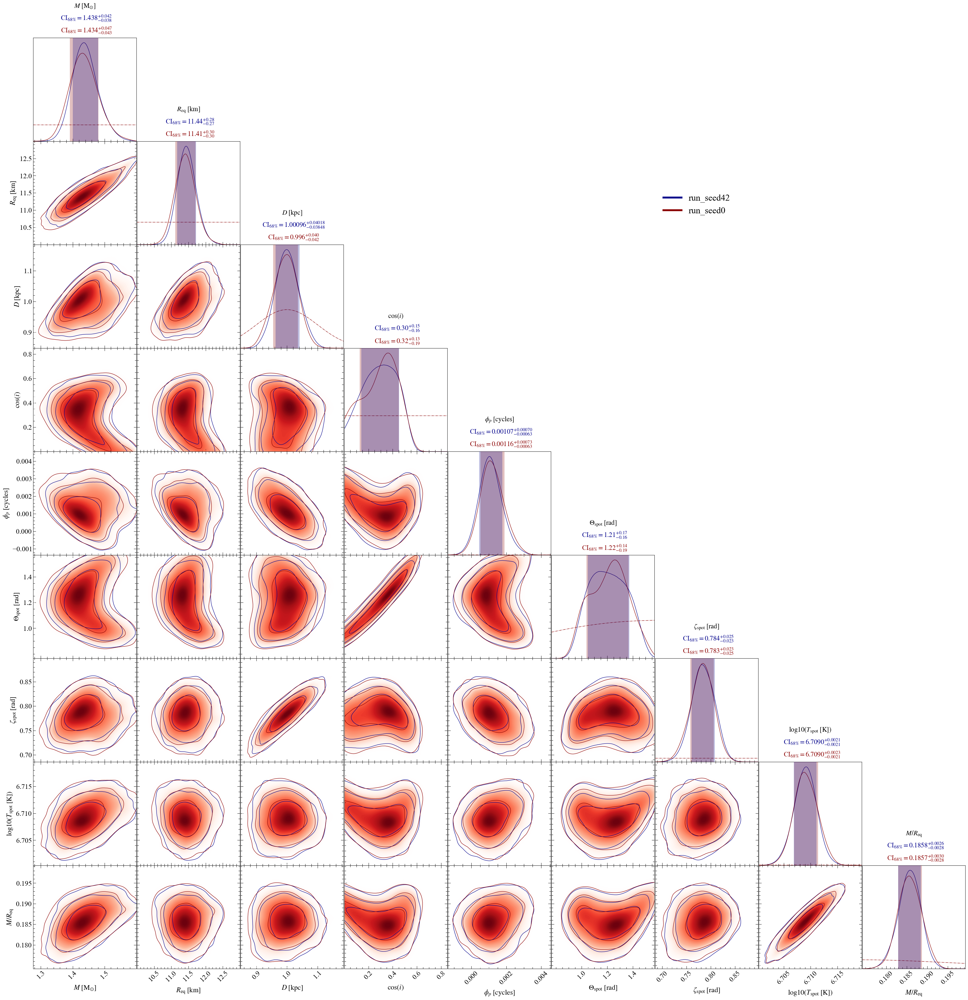

In [17]:
pp = xpsi.PostProcessing.CornerPlotter([ST.runs])
_ = pp.plot(
     params=ST.names,
     IDs=OrderedDict([('ST', ['run_seed0','run_seed42',]),]),
     prior_density=True,
     KL_divergence=True,
     ndraws=5e4,
     combine=False, combine_all=True, only_combined=False, overwrite_combined=True,
     param_plot_lims={},
     bootstrap_estimators=False,
     bootstrap_density=False,
     n_simulate=200,
     crosshairs=False,
     write=False,
     ext='.png',
     maxdots=3000,
     root_filename='run',
     credible_interval_1d=True,
     credible_interval_1d_all_show=True, # To show credible intervals for all runs/models
     show_vband=[0,1],                   # To list which vertical colored bands are shown in 1D-posteriors
                                         #  0 for run_seed0,  1 for run_seed42
     annotate_credible_interval=True,
     compute_all_intervals=False,
     sixtyeight=True,
     axis_tick_x_rotation=45.0,
     num_plot_contours=3,
     subplot_size=4.0,
     legend_corner_coords=(0.675,0.8),
     legend_frameon=False,
     scale_attrs=OrderedDict([('legend_fontsize', 2.0),
                              ('axes_labelsize', 1.35),
                              ('axes_fontsize', 'axes_labelsize'),
                             ]
                            ),
     colormap='Reds',
     shaded=-1,
     rasterized_shade=True,
     no_ylabel=True,
     no_ytick=True,
     lw=1.0,
     lw_1d=1.0,
     filled=False,
     normalize=True,
     veneer=True,
     tqdm_kwargs={'disable': False},
     lengthen=2.0,
     embolden=1.0,
     nx=500)

# If you have multiple runs/models, you can increase the legend linewidth
for legobj in _.legend.legend_handles:
        legobj.set_linewidth(5.0)

We can also obtain the credible intervals shown on the plot in the form of a list:

In [18]:
credible_intervals=pp.credible_intervals

In [19]:
# Printing the first one:
print(credible_intervals["ST_run_seed0"])

[[ 1.434e+00 -4.300e-02  4.700e-02]
 [ 1.141e+01 -3.000e-01  3.000e-01]
 [ 9.960e-01 -4.200e-02  4.000e-02]
 [ 3.200e-01 -1.900e-01  1.300e-01]
 [ 1.160e-03 -6.300e-04  7.300e-04]
 [ 1.220e+00 -1.900e-01  1.400e-01]
 [ 7.830e-01 -2.500e-02  2.300e-02]
 [ 6.709e+00 -2.100e-03  2.300e-03]
 [ 1.857e-01 -2.800e-03  3.000e-03]]


In [20]:
# Printing the second one:
print(credible_intervals["ST_run_seed42"])

[[ 1.43800e+00 -3.80000e-02  4.20000e-02]
 [ 1.14400e+01 -2.70000e-01  2.80000e-01]
 [ 1.00096e+00 -3.84800e-02  4.01800e-02]
 [ 3.00000e-01 -1.60000e-01  1.50000e-01]
 [ 1.07000e-03 -6.30000e-04  7.00000e-04]
 [ 1.21000e+00 -1.60000e-01  1.70000e-01]
 [ 7.84000e-01 -2.30000e-02  2.50000e-02]
 [ 6.70900e+00 -2.10000e-03  2.10000e-03]
 [ 1.85800e-01 -2.80000e-03  2.60000e-03]]


Assuming that one knows the values that have been used to produce the data and wants to show them:

In [21]:
# Our case: 
ST.truths={'mass': 1.4,                               # Mass in solar Mass
          'radius': 12.,                              # Equatorial radius in km
          'distance': 1.0,                            # Distance in kpc
          'cos_inclination': math.cos(60*np.pi/180),  # Cosine of Earth inclination to rotation axis
          'p__phase_shift': 0.0,                    # Phase shift
          'p__super_colatitude': 70*np.pi/180,      # Colatitude of the centre of the superseding region
          'p__super_radius': 0.75,                  # Angular radius of the (circular) superseding region
          'p__super_temperature':6.7}               # Temperature in log 

ST.truths['compactness']=gravradius(ST.truths['mass'])/ST.truths['radius']

In [22]:
# Loading the run again :)

ST.runs = xpsi.Runs.load_runs(ID='ST',
                               run_IDs=['run'],
                               roots=['ST_live_1000_eff_0.3_seed0'],
                               base_dirs=['../../examples/examples_fast/Outputs/'],
                               use_nestcheck=[True],
                               kde_settings=getdist_kde_settings,
                               likelihood=ST.likelihood,
                               names=ST.names,
                               bounds=ST.bounds,
                               labels=ST.labels,
                               truths=ST.truths, # Adding this line
                               implementation='multinest',
                               overwrite_transformed=True)

Change output files to .npy to speed up post-processing


Executing posterior density estimation...
Curating set of runs for posterior plotting...
Run set curated.
Constructing lower-triangle posterior density plot via Gaussian KDE:
plotting:  ['mass', 'radius']
plotting:  ['mass', 'distance']
plotting:  ['mass', 'cos_inclination']
plotting:  ['mass', 'p__phase_shift']
plotting:  ['mass', 'p__super_colatitude']
plotting:  ['mass', 'p__super_radius']
plotting:  ['mass', 'p__super_temperature']
plotting:  ['mass', 'compactness']
plotting:  ['radius', 'distance']
plotting:  ['radius', 'cos_inclination']
plotting:  ['radius', 'p__phase_shift']
plotting:  ['radius', 'p__super_colatitude']
plotting:  ['radius', 'p__super_radius']
plotting:  ['radius', 'p__super_temperature']
plotting:  ['radius', 'compactness']
plotting:  ['distance', 'cos_inclination']
plotting:  ['distance', 'p__phase_shift']
plotting:  ['distance', 'p__super_colatitude']
plotting:  ['distance', 'p__super_radius']
plotting:  ['distance', 'p__super_temperature']
plotting:  ['dista

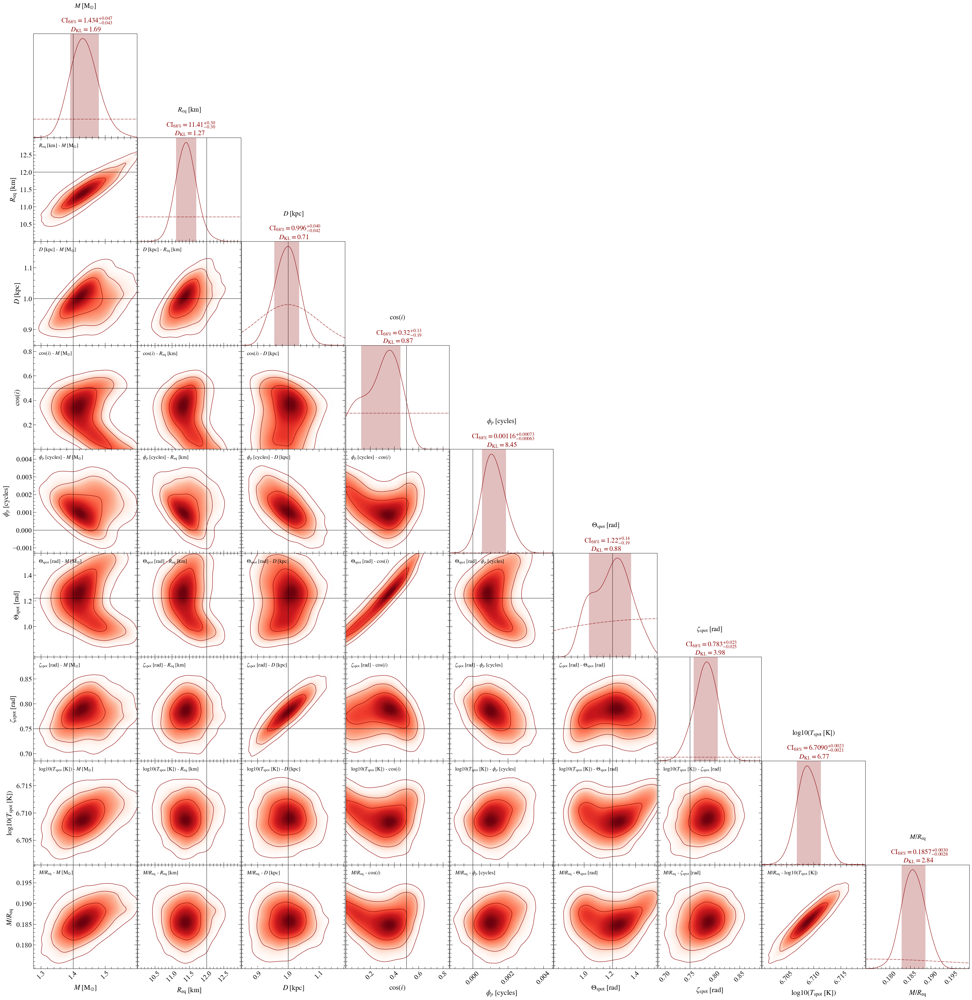

In [23]:
pp = xpsi.PostProcessing.CornerPlotter([ST.runs])
_ = pp.plot(
     params=ST.names,
    
     IDs=OrderedDict([('ST', ['run',]),]),
     prior_density=True,
     KL_divergence=True,
     ndraws=5e4,
     combine=False, combine_all=True, only_combined=False, overwrite_combined=True,
     param_plot_lims={},
     labels_2D = True,
     bootstrap_estimators=False,
     bootstrap_density=False,
     n_simulate=200,
     crosshairs=True, # Turn this to true
     write=False,
     ext='.png',
     maxdots=3000,
     root_filename='run',
     credible_interval_1d=True,
     credible_interval_1d_show_all=True,
     annotate_credible_interval=True,
     compute_all_intervals=False,
     sixtyeight=True,
     axis_tick_x_rotation=45.0,
     num_plot_contours=3,
     subplot_size=4.0,
     legend_corner_coords=(0.675,0.8),
     legend_frameon=False,
     scale_attrs=OrderedDict([('legend_fontsize', 2.0),
                              ('axes_labelsize', 1.35),
                              ('axes_fontsize', 'axes_labelsize'),
                             ]
                            ),
      colormap='Reds',
     shaded=-1,
     rasterized_shade=True,
     no_ylabel=True,
     no_ytick=True,
     lw=1.0,
     lw_1d=1.0,
     filled=False,
     normalize=True,
     veneer=True,
     #contour_colors=['orange'],
     tqdm_kwargs={'disable': False},
     lengthen=2.0,
     embolden=1.0,
     nx=500)


## Residual plot

Now let’s plot the standardised Poissonian residuals of the first run. You have different options of what to plot that are proposed here. You can choose to plot the bolometric pulse (data and model with the errorbars), the clustering information and to blur the residuals.

The posterior predictive model is plotted and the errorbars represents the 16th and 84th percentile of the distribution. If computing many samples for the posterior predictive is too long, you can also choose a number of Poisson realisation (default is 1) for each sample to artificially increase your sample size. Bear in mind that it is recommended for this value not to be too high, otherwise the posterior predictive uncertainty will loose information of the parameters distribution.

Declaring plot class settings...
Settings declared.
Instantiating a residual plotter for posterior checking...
Residual plotter instantiated.
Plotting signals for posterior checking...
Curating set of runs for posterior plotting...
Run set curated.
Handling posterior ST...
Checking whether an existing cache can be read:
Creating new cache file...
Attempting to archive existing cache file in a subdirectory...
Targeting subdirectory: ./archive.
Exisiting cache file archived in subdirectory ./archive.
Initialising cache file...
Cache file initialised.
Cache file created.
Cache state determined.


Signal caching loop:   0%|          | 0/100 [00:00<?, ?it/s]

ResidualPlot object iterating over samples...
ResidualPlot object finished iterating.
ResidualPlot object finalizing...
ResidualPlot object finalized.
Writing plot to disk...
ResidualPlot instance plot will be written to path ./ST.run__signalplot_residuals.pdf...
Written.
Handled posterior ST.
Plotted signals for posterior checking.


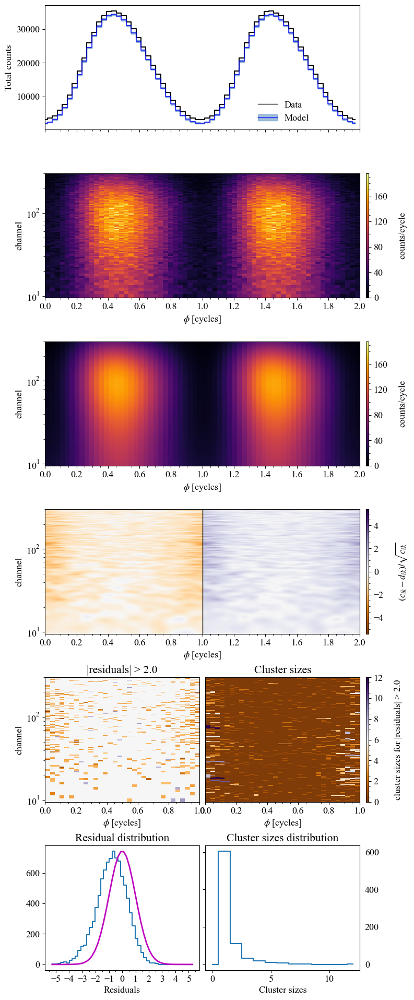

In [24]:
# Now let's plot the resudual of the first run.
pp = xpsi.SignalPlotter([ST.runs])
# Setting next the yticks for the 3 plots, alternating the main plot and the color bar y-ticks.
# (None if using automatic tikcs)
xpsi.ResidualPlot.declare_settings(yticks=[[10,30,100],None,[10,30,100],None,[10,30,100],None])
plots = {'ST': xpsi.ResidualPlot(
                 parameters_vector= None, #list( ST.truths.values())[:-1],
                 plot_pulse=True,
                 legend_pulse_coords=( 0.65, 0.3 ),
                 n_realisation_per_sample=5, # Number of realisation of each model to compute posterior predictive error
                 blur_residuals=True,
                 plot_clusters=True,
                 threshlim=2.0,
                 mu=0.0,
                 sigma=1.0,
                 nbins=50,
                 yscale='log',
)}
pp.plot(IDs=OrderedDict([('ST', ['run']),
                        ]),
        combine=False, # use these controls if more than one run for a posterior
        combine_all=False,
        force_combine=False,
        only_combined=False,
        force_cache=True,
        nsamples=100,
        plots = plots )

pp.plots["ST"].fig

The bolometric $\chi^2$, ie the $\chi^2$ value of the pulse model plotted, can be obtained by a simple call. 

In [25]:
pp.plots["ST"].bolometric_chi2

5569.886200503381

For all the post processing you can also choose a specific parameter vector `parameters_vector` to make the associated plot instead of drawing random samples from the posterior. In this case, and when the number of sample is low (<100), we plot the Poisson error of the model instead of the posterior predictive error. Here we set the parameter vector to the ground truth - this can be done for any of the following plots :

Declaring plot class settings...
Settings declared.
Instantiating a residual plotter for posterior checking...
Residual plotter instantiated.
Plotting signals for posterior checking...
Curating set of runs for posterior plotting...
Run set curated.
Handling posterior ST...
Plotting the model for the provided parameters vector.
Checking whether an existing cache can be read:
Creating new cache file...
Attempting to archive existing cache file in a subdirectory...
Targeting subdirectory: ./archive.
Exisiting cache file archived in subdirectory ./archive.
Initialising cache file...
Cache file initialised.
Cache file created.
Cache state determined.


Signal caching loop:   0%|          | 0/1 [00:00<?, ?it/s]

ResidualPlot object iterating over samples...
ResidualPlot object finished iterating.
ResidualPlot object finalizing...
ResidualPlot object finalized.
Writing plot to disk...
ResidualPlot instance plot will be written to path ./ST.run__signalplot_residuals.pdf...
Written.
Handled posterior ST.
Plotted signals for posterior checking.


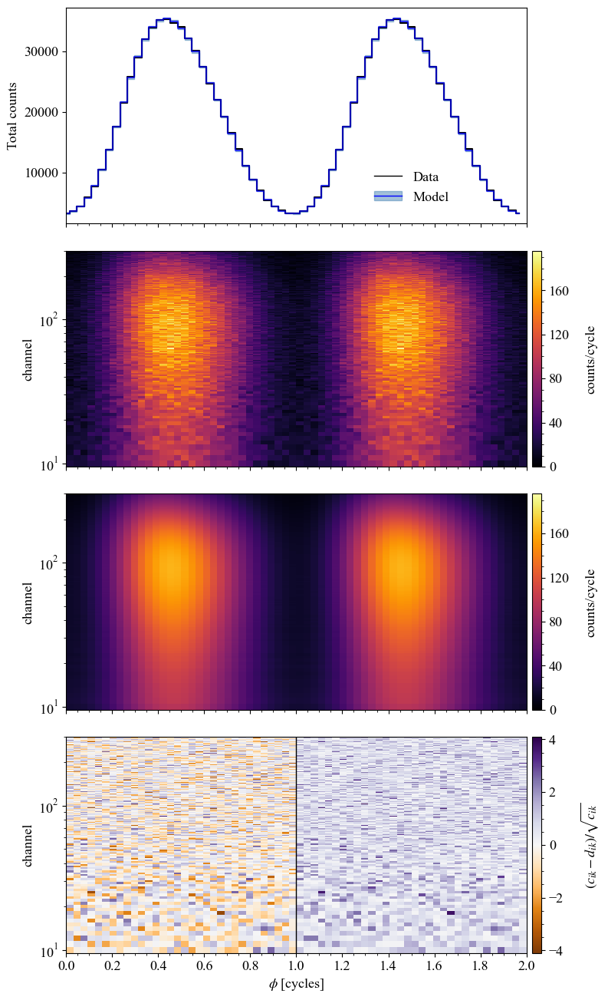

In [26]:
# Now let's plot the resudual of the first run.
pp = xpsi.SignalPlotter([ST.runs])
# Setting next the yticks for the 3 plots, alternating the main plot and the color bar y-ticks.
# (None if using automatic tikcs)
xpsi.ResidualPlot.declare_settings(yticks=[[10,30,100],None,[10,30,100],None,[10,30,100],None])
plots = {'ST': xpsi.ResidualPlot(
                 parameters_vector= list( ST.truths.values())[:-1],
                 plot_pulse=True,
                 legend_pulse_coords=( 0.75, 0.3 ),
                 n_realisation_per_sample=1, # Number of realisation of each model to compute posterior predictive error
                 blur_residuals=False,
                 plot_clusters=False,
                 threshlim=2.0,
                 mu=0.0,
                 sigma=1.0,
                 nbins=50,
                 yscale='log',
)}
pp.plot(IDs=OrderedDict([('ST', ['run']),
                        ]),
        combine=False, # use these controls if more than one run for a posterior
        combine_all=False,
        force_combine=False,
        only_combined=False,
        force_cache=True,
        plots = plots )

pp.plots["ST"].fig

The histogram of 2D residuals can also be plotted on its own. This is useful to check the residuals distribution of data with and without phase information.

Instantiating a 1D residual plotter for residual distribution checking...
Declaring plot class settings...
Settings declared.
Residual plotter instantiated.
Plotting signals for posterior checking...
Curating set of runs for posterior plotting...
Run set curated.
Handling posterior ST...
Checking whether an existing cache can be read:
Creating new cache file...
Attempting to archive existing cache file in a subdirectory...
Targeting subdirectory: ./archive.
Exisiting cache file archived in subdirectory ./archive.
Initialising cache file...
Cache file initialised.
Cache file created.
Cache state determined.


Signal caching loop:   0%|          | 0/100 [00:00<?, ?it/s]

Residual1DPlot object iterating over samples...
Residual1DPlot object finished iterating.
ResidualPlot object finalizing...
ResidualPlot object finalized.
Writing plot to disk...
Residual1DPlot instance plot will be written to path ./ST.run__signalplot_1dresiduals.pdf...
Written.
Handled posterior ST.
Plotted signals for posterior checking.


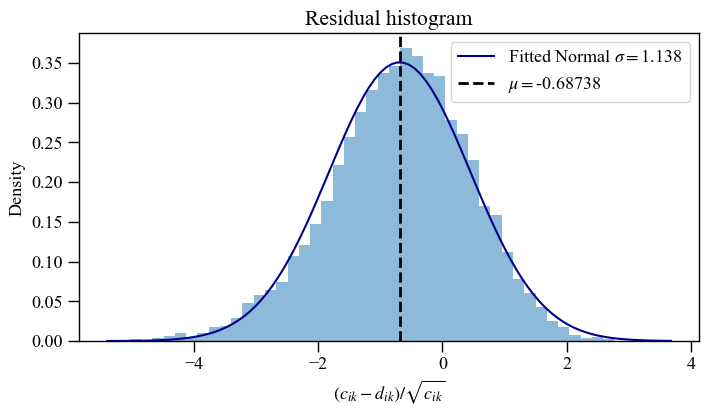

In [27]:
# Now let's plot the resudual of the first run.
pp = xpsi.SignalPlotter([ST.runs])
# Setting next the yticks for the 3 plots, alternating the main plot and the color bar y-ticks.
# (None if using automatic tikcs)
plots = {'ST': xpsi.Residual1DPlot(
                 parameters_vector= None, #list( ST.truths.values())[:-1],
                 nbins=50,
                 plot_fit=True
)}
pp.plot(IDs=OrderedDict([('ST', ['run']),
                        ]),
        combine=False, # use these controls if more than one run for a posterior
        combine_all=False,
        force_combine=False,
        only_combined=False,
        force_cache=True,
        nsamples=100,
        plots = plots )

pp.plots["ST"].fig


## Signal plots

Now let’s plot pulse and spectrum plots for the inferred signals.

In [29]:
ST.likelihood.clear_cache()
p=[1.4,12,1.,math.cos(60*np.pi/180),0.0,70*np.pi/180, 0.75,6.7]
ST.likelihood.check(None, [-3.2552616905e+04], 1.0e-5, physical_points=[p])

Checking likelihood and prior evaluation before commencing sampling...
Not using ``allclose`` function from NumPy.
Using fallback implementation instead.
Checking closeness of likelihood arrays:
-3.2552616905e+04 | -3.2552616905e+04 .....
Closeness evaluated.
Log-likelihood value checks passed on root process.
Checks passed.


'Log-likelihood value checks passed on root process.'

In [30]:
pp = xpsi.SignalPlotter([ST.runs])

In [31]:
# Setting next the yticks: First to the 4 main plots and then to the 4 color bars.
xpsi.PulsePlot.declare_settings(extension='.png',yticks=[[0.2,0.5,1.0],None,[10,30,100],None,None,None,None,None])
pp.plot(
     IDs=OrderedDict([('ST', ['run',]),]),  
   nsamples=200,
   plots = {         
            'ST': xpsi.PulsePlot(use_fgivenx=True,
                                        comp_expectation_line_kwargs=dict(color='b',
                                                                           ls='-.',
                                                                           lw=0.75,
                                                                           alpha=1.0),
                                        show_components=True,
                                        fig_dir='.',
                                        write=True,
                                        root_filename= 'ST_model_signal',),       
            }
       )        


Declaring plot class settings...
Settings declared.
Instantiating a pulse-profile plotter for posterior checking...
Pulse-profile plotter instantiated.
Plotting signals for posterior checking...
Curating set of runs for posterior plotting...
Run set curated.
Handling posterior ST...
Checking whether an existing cache can be read:
Creating new cache file...
Attempting to archive existing cache file in a subdirectory...
Targeting subdirectory: ./archive.
Exisiting cache file archived in subdirectory ./archive.
Initialising cache file...
Cache file initialised.
Cache file created.
Cache state determined.


Signal caching loop:   0%|          | 0/200 [00:00<?, ?it/s]

PulsePlot object iterating over samples...
Adding credible intervals on the incident photon flux signal as function of phase...


  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/999 [00:00<?, ?it/s]

Credible intervals added.
Added conditional posterior contours for incident signal.
Adding credible intervals on the count-rate signal as function of phase...


... (3 outputs left out)

/home/saltuomo/xpsi/xpsi_group/xpsi/xpsi/PostProcessing/_signalplot.py:443: UserWarning: Adding colorbar to a different Figure <Figure size 800x1600 with 8 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(cb, cax=ax_cb, ticks=[1,2,3]) # ticks units = sigmas


Credible intervals added.
Added conditional posterior contours for registered signal.
PulsePlot object finished iterating.
PulsePlot object finalizing...
PulsePlot object finalized.
Writing plot to disk...
PulsePlot instance plot will be written to path ./ST_model_signal__ST.run__signalplot_pulse.png...


/home/saltuomo/xpsi/xpsi_group/xpsi/xpsi/PostProcessing/_pulse.py:460: UserWarning: Adding colorbar to a different Figure <Figure size 800x1600 with 8 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  self._incident_cb = plt.colorbar(incident, cax=self._ax_cb,
/home/saltuomo/xpsi/xpsi_group/xpsi/xpsi/PostProcessing/_pulse.py:540: UserWarning: Adding colorbar to a different Figure <Figure size 800x1600 with 8 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  self._registered_cb = plt.colorbar(registered,


Written.
Handled posterior ST.
Plotted signals for posterior checking.


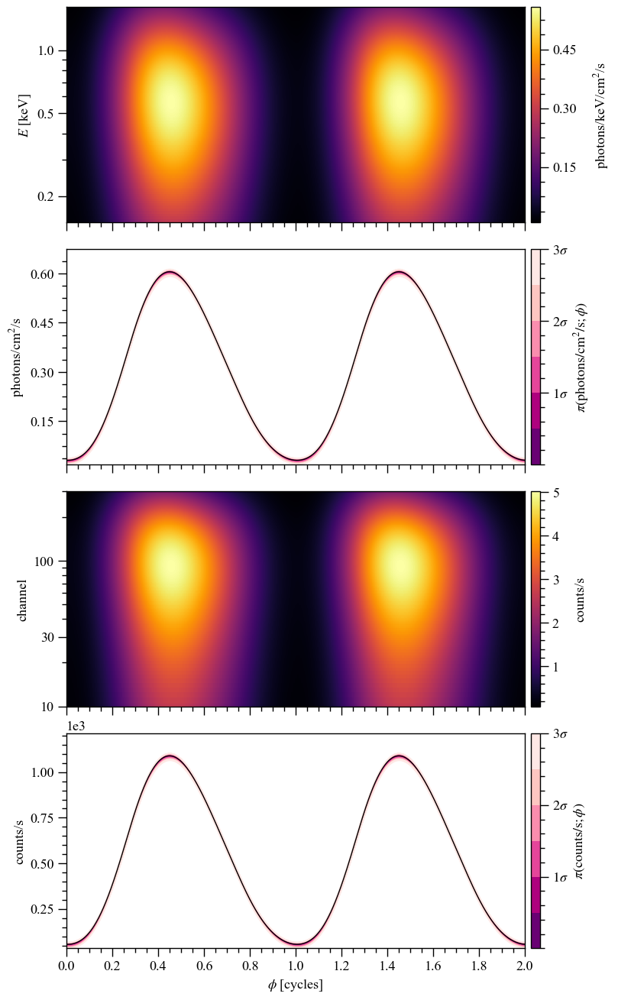

In [32]:
pp.plots['ST'].fig

In [33]:
# Setting next both the xticks and yticks: First to the 3 main plots and then to the 3 color bars.
xpsi.SpectrumPlot.declare_settings(extension='.png',xticks=[[0.2,0.5,1.0],[10,30,100],[10,30,100],\
                                                            None,None,None],\
                                   yticks=[[0.1,0.2],None,[0.5,1.0,2.0],None,None,None]
                                  )
pp.plot(
     IDs=OrderedDict([('ST', ['run',]),]),     
   nsamples=200,
   plots = {
            'ST': xpsi.SpectrumPlot(use_fgivenx=True,
                                        expectation_line_kwargs=dict(color='k',
                                                                      ls='-',
                                                                      lw=1.0,
                                                                      alpha=1.0),
                                         sample_line_kwargs=dict(color='pink',
                                                                 ls='-',
                                                                 lw=0.05,
                                                                 alpha=1.0),
                                         comp_expectation_line_kwargs=dict(color='b',
                                                                        ls='-.',
                                                                        lw=0.75,
                                                                        alpha=1.0),
                                         show_attenuated=False,#True,
                                         show_components=True,
                                         fig_dir='.',
                                         write=True,
                                         root_filename= 'ST_spectra',
                                       ),       
           }
       ) 

Declaring plot class settings...
Settings declared.
Instantiating a spectrum plotter for posterior checking...
Spectrum plotter instantiated.
Plotting signals for posterior checking...
Curating set of runs for posterior plotting...
Run set curated.
Handling posterior ST...
Checking whether an existing cache can be read:
Creating new cache file...
Attempting to archive existing cache file in a subdirectory...
Targeting subdirectory: ./archive.
Exisiting cache file archived in subdirectory ./archive.
Initialising cache file...
Cache file initialised.
Cache file created.
Cache state determined.


Signal caching loop:   0%|          | 0/200 [00:00<?, ?it/s]

SpectrumPlot object iterating over samples...
Adding credible intervals on the incident specific photon flux spectrum...


  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/640 [00:00<?, ?it/s]

Credible intervals added.
Adding credible intervals on the count-rate spectrum...


... (3 outputs left out)

/home/saltuomo/xpsi/xpsi_group/xpsi/xpsi/PostProcessing/_signalplot.py:443: UserWarning: Adding colorbar to a different Figure <Figure size 800x1200 with 6 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(cb, cax=ax_cb, ticks=[1,2,3]) # ticks units = sigmas


Credible intervals added.
Added conditional posterior contours for incident spectrum.
SpectrumPlot object finished iterating.
SpectrumPlot object finalizing...


/home/saltuomo/xpsi/xpsi_group/xpsi/xpsi/PostProcessing/_spectrum.py:804: UserWarning: Adding colorbar to a different Figure <Figure size 800x1200 with 6 Axes> than <Figure size 640x480 with 0 Axes> which fig.colorbar is called on.
  self._registered_cb = plt.colorbar(registered,


SpectrumPlot object finalized.
Writing plot to disk...
SpectrumPlot instance plot will be written to path ./ST_spectra__ST.run__signalplot_spectrum.png...
Written.
Handled posterior ST.
Plotted signals for posterior checking.


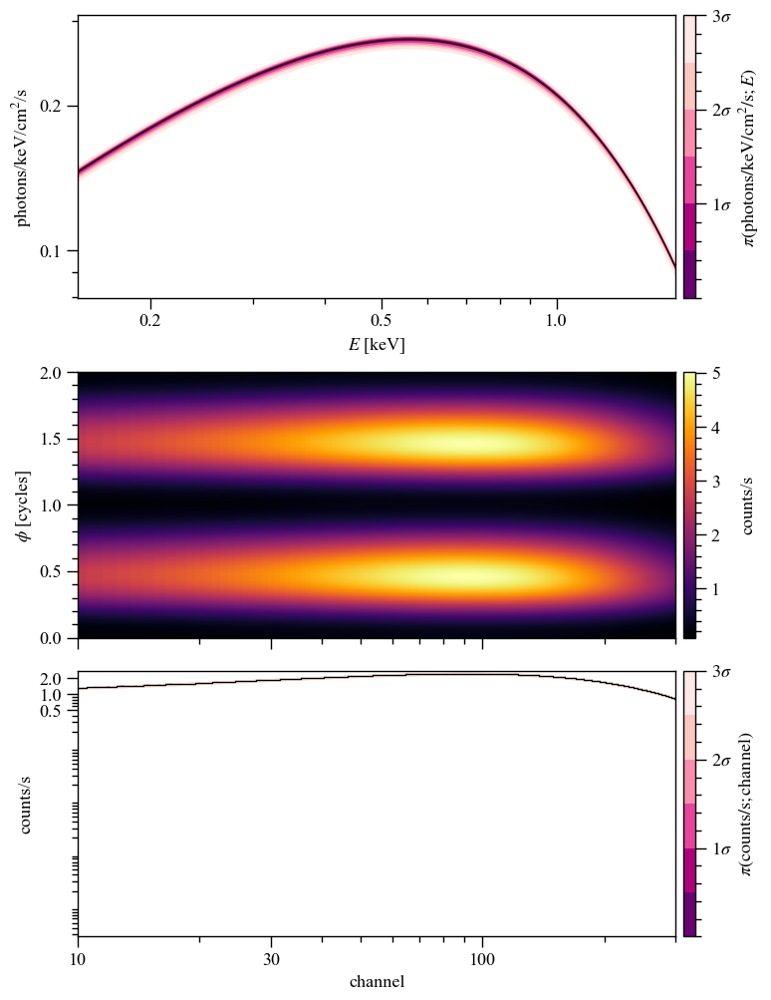

In [34]:
pp.plots['ST'].fig

## P-P plot

In order to show if the inference is unbiased, a P-P plot can be made where P could stand for probability, percent or proportion. This is something that is often done is graviational wave science (see for example Figure A1 from [this](https://arxiv.org/pdf/2006.00714) paper). The gray regions cover the cumulative 1-, 2-, and 3-$\sigma$ credible intervals in order of decreasing opacity (their "size" is thus dependent on the amount of inference runs used). Each colored line tracks the cumulative fraction of events within this credible interval for a different parameter. For unbiased recovery, the lines should lie perfectly along the diagonal.

The function below demonstrates how to generate a P-P plot. In this example, the P-P plot is created for a single parameter across just two inference runs. Note that in practice, P-P plots are often generated using a larger number of inference runs to improve statistical robustness.

In [35]:
def get_credible_interval(filepath: str, param_to_plot: str, params_data: list, truth: float):
    """
    Calculate the credible interval for a parameter in an inference run.

    This function computes the percentage of inferred parameter values 
    that fall below a given true value, weighted by the sampling weights.

    Parameters
    ----------
    filepath : str
        Path to the output `.txt` file containing the sampling weights and parameter data.
    param_to_plot : str
        Name of the parameter for which the credible interval is to be calculated.
    params_data : list
        List of parameter names in the same order as they appear in the output file.
    truth : float
        The true value of the parameter.

    Returns
    -------
    float
        The credible interval, expressed as the weighted fraction of samples 
        with parameter values less than the true value.
    """
    # load the data and its weights 
    data = np.loadtxt(filepath)
    weights = data[:,0]

    # get the samples. Add 2, because column 0 is weights 
    # and column 1 is -2*loglikelihood
    idx_param = params_data.index(param_to_plot) + 2
    data_param = data[:,idx_param]

    # get indices of all samples that fall below the true value 
    filter = np.where(data_param < truth)

    # get corresponding weights 
    weights_below_true_val = weights[filter]

    credible_interval = np.sum(weights_below_true_val)/np.sum(weights)

    return credible_interval

def make_pp_plot(credible_intervals: list): 
    """
    Create a PP-plot for a single parameter. The PP-plot is generated
    from multiple inference runs, all sharing the same true value. The 
    plot visualizes how well the inferred credible intervals recover 
    the true parameter value. Credible intervals (68%, 95%, and 99.7%) 
    are shaded in the plot to indicate expected variations under ideal condition

    Parameters
    ----------
    credible_intervals : list
        List of credible intervals from various inference runs, representing the 
        fraction of inferred parameter values below the true value for each run.
    """
    fig, ax = plt.subplots(figsize=(6,6))

    x_values = np.linspace(0., 0.999, 1001)       

    # plot grey area 
    credible_interval=[0.68, 0.95, 0.997]
    credible_interval_alpha = [0.3,0.3/2,0.3/3]

    # determine number of credible intervals to plot 
    N = len(credible_intervals)

    for ci, alpha in zip(credible_interval, credible_interval_alpha):

        edge_of_bound = (1. - ci) / 2.
        lower = binom.ppf(1 - edge_of_bound, N, x_values) / N
        upper = binom.ppf(edge_of_bound, N, x_values) / N
        # The binomial point percent function doesn't always return 0 @ 0,
        # so set those bounds explicitly to be sure
        lower[0] = 0
        upper[0] = 0
        ax.fill_between(x_values, lower, upper, alpha=alpha, color='grey')

    # plot lines 
    x_values = np.linspace(0., 0.999, 1001)  

    # now, plot the credible intervals
    pp = np.array([sum(credible_intervals < xx)/len(credible_intervals) for xx in x_values])
    ax.plot(x_values, pp)

    ax.set_xlabel("Credible interval")
    ax.set_ylabel("Fraction of events in credible interval")

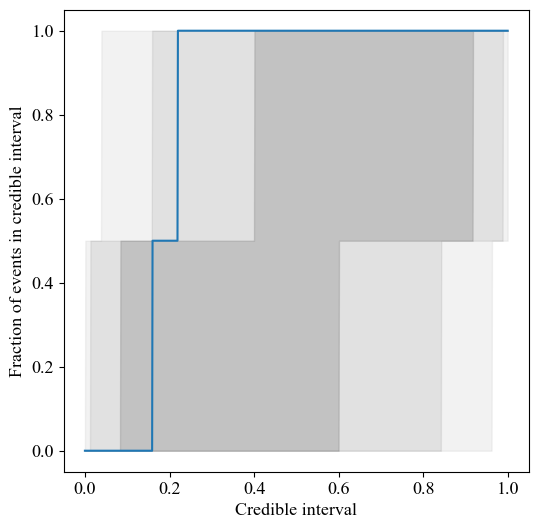

In [36]:
files = ['../../examples/examples_fast/Outputs/ST_live_1000_eff_0.3_seed0.txt', 
         '../../examples/examples_fast/Outputs/ST_live_1000_eff_0.3_seed42.txt']

credible_intervals = []
for file in files:
    credible_interval = get_credible_interval(file, 'mass', ST.names, ST.truths['mass'])
    credible_intervals.append(credible_interval)

make_pp_plot(credible_intervals)